# PSF photometric recalibration of an SDSS spectrum

This notebook mirrors the main SDSS tutorial, but also:

- queries SDSS PSF magnitudes for the same object
- fits the spectrum without PSF photometry
- fits the spectrum again with `use_psf_phot=True`
- compares the fiber-only and PSF-constrained results

This notebook demonstrates a spectral recalibration scheme in `JAXQSOFit` that connects the SDSS fiber spectrum to overlapping broadband PSF photometry. `JAXQSOFit` is still only doing spectral fitting: the photometric points are an extra likelihood on synthetic magnitudes computed from the fitted spectral model. The PSF bands therefore need useful transmission overlap with the observed spectral wavelength coverage. For full joint spectrum + broadband SED modeling, use `jaxsedfit` instead.

The spectrum is fit on its native fiber scale, while a second likelihood compares synthetic PSF magnitudes from a PSF-space version of the model to the observed SDSS PSF magnitudes. In that PSF-space model, a gray offset term `delta_m_psf` captures overall spectrophotometric or epoch-to-epoch normalization differences, while a host-suppression term `eta_psf` reduces the contribution of spatially extended components in the PSF aperture. The key idea is that the AGN continuum, host galaxy, broad-line emission, and narrow-line emission do not contribute in the same way to fiber and PSF measurements. The AGN continuum and broad lines are treated as compact, unresolved components, while the stellar host and narrow lines are treated as more extended. Because the AGN and host also have different spectral shapes, changing the relative contribution of the extended components changes the broadband colors in a characteristic way. By fitting the fiber spectrum and the overlapping PSF photometry simultaneously, the model can use those color differences to separate AGN and host light more cleanly, infer PSF-consistent components, and estimate more realistic host fractions in the photometric aperture.

We model the observed SDSS fiber spectrum and overlapping SDSS PSF photometry jointly as a spectral calibration problem, not as a full SED fit.

For the rest-frame spectral model, we write

$$
f_{\mathrm{fiber}}(\lambda)
=
f_{\mathrm{AGN}}(\lambda)
+
f_{\mathrm{host}}(\lambda)
+
f_{\mathrm{lines,br}}(\lambda)
+
f_{\mathrm{lines,na}}(\lambda),
$$

where the AGN term includes the power law, Fe II, and Balmer continuum components, and the emission-line model is split into broad and narrow components.

The fiber-spectrum likelihood is

$$
F_i^{\mathrm{obs}}
\sim
\mathcal{N}\!\left(
f_{\mathrm{fiber}}(\lambda_i),
\,
\sigma_{\mathrm{tot},i}^2
\right),
$$

with total per-pixel uncertainty

$$
\sigma_{\mathrm{tot},i}^2
=
\sigma_i^2
+
\left(f_{\mathrm{frac}}\,|f_{\mathrm{fiber}}(\lambda_i)|\right)^2
+
\sigma_{\mathrm{add}}^2,
$$

where $\sigma_i$ is the measured spectral error, and $f_{\mathrm{frac}}$ and $\sigma_{\mathrm{add}}$ are fractional and additive jitter terms.

To compare with PSF photometry, we construct a PSF-space model

$$
f_{\mathrm{PSF}}(\lambda)
=
s_{\mathrm{PSF}}
\left[
f_{\mathrm{AGN}}(\lambda)
+
\eta_{\mathrm{PSF}}\,f_{\mathrm{host}}(\lambda)
+
f_{\mathrm{lines,br}}(\lambda)
+
\eta_{\mathrm{PSF}}\,f_{\mathrm{lines,na}}(\lambda)
\right],
$$

where

$$
s_{\mathrm{PSF}} = 10^{-0.4\,\Delta m_{\mathrm{PSF}}},
$$

$\Delta m_{\mathrm{PSF}}$ is a gray magnitude offset between the fiber spectral scale and the PSF photometric scale, and $\eta_{\mathrm{PSF}} \in [0,1]$ controls how much of the extended host-like components contribute in the PSF aperture. In this version of the model, broad lines are treated like the unresolved AGN, while narrow lines are treated like the extended host.

For each photometric band $b$, we compute a synthetic AB magnitude from the PSF-space model,

$$
m_b^{\mathrm{syn}}
=
-2.5\log_{10}\!\left(f_{\nu,b}\right)-48.60,
$$

with

$$
f_{\nu,b}
=
\frac{
\int f_{\lambda}^{\mathrm{PSF}}(\lambda)\,T_b(\lambda)\,\lambda\,d\lambda
}{
\int T_b(\lambda)\,c/\lambda\,d\lambda
},
$$

where $T_b(\lambda)$ is the filter transmission curve.

The PSF-photometry likelihood is then

$$
m_b^{\mathrm{obs}}
\sim
\mathcal{N}\!\left(
m_b^{\mathrm{syn}},
\,
\sigma_{m,b}^2 + \sigma_{\mathrm{phot,extra}}^2
\right),
$$

where $\sigma_{m,b}$ is the catalog magnitude uncertainty and $\sigma_{\mathrm{phot,extra}}$ is an additional photometric scatter term.

The spectral-recalibration likelihood used here is

$$
\mathcal{L}
=
\prod_i
p\!\left(F_i^{\mathrm{obs}} \mid f_{\mathrm{fiber}}(\lambda_i)\right)
\;
\prod_b
p\!\left(m_b^{\mathrm{obs}} \mid m_b^{\mathrm{syn}}\right).
$$

A useful derived quantity is the PSF-space host fraction at wavelength $\lambda$,

$$
f_{\mathrm{host,PSF}}(\lambda)
=
\frac{f_{\mathrm{host}}^{\mathrm{PSF}}(\lambda)}
     {f_{\mathrm{AGN}}^{\mathrm{PSF}}(\lambda)+f_{\mathrm{host}}^{\mathrm{PSF}}(\lambda)}
=
\frac{\eta_{\mathrm{PSF}}\,f_{\mathrm{host}}(\lambda)}
     {f_{\mathrm{AGN}}(\lambda)+\eta_{\mathrm{PSF}}\,f_{\mathrm{host}}(\lambda)},
$$

since the overall gray scale factor $s_{\mathrm{PSF}}$ cancels in the ratio.

Likewise, the PSF-space narrow-line fraction is reduced by the same $\eta_{\mathrm{PSF}}$ factor, while the broad-line contribution follows the unresolved AGN scaling.

In [1]:
from dataclasses import replace

import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord
from astroquery.sdss import SDSS

from jaxqsofit import (
    ContinuumConfig,
    FitConfig,
    HostConfig,
    InferenceConfig,
    JAXQSOFit,
    LineConfig,
    Observation,
    OutputConfig,
    PSFPhotometryData,
    SpectroscopyData,
)

## 1. Download the spectrum and the PSF magnitudes

`SDSS.query_region` can return photometric columns together with the spectroscopic match. We keep the most recent spectrum of the object.

In [2]:
bands = ["u", "g", "r", "i", "z"]
coord = SkyCoord("01h05m14.10s -01d02m22.9s")  # SDSS J010514.10-010222.9
matches = SDSS.query_region(
    coord,
    spectro=True,
    radius=5 * u.arcsec,
    photoobj_fields=[f"psfMag_{b}" for b in bands] + [f"psfMagErr_{b}" for b in bands],
    specobj_fields=["plate", "mjd", "fiberID", "run2d"],
)
matches.sort("mjd")
latest = matches[-1:]
hdul = SDSS.get_spectra(matches=latest)[0]

spec = hdul[1].data
wave = 10 ** spec["loglam"]
flux = spec["flux"]
with np.errstate(divide="ignore"):
    err = 1 / np.sqrt(spec["ivar"])
z = hdul[2].data["Z"][0]
resolving_power = 1 / (2.355 * np.log(10) * 1e-4 * np.median(spec["wdisp"]))

psf_mags = [float(latest[f"psfMag_{b}"][0]) for b in bands]
psf_mag_errs = [float(latest[f"psfMagErr_{b}"][0]) for b in bands]
print(f"z = {z:.4f}; PSF magnitudes:", dict(zip(bands, psf_mags)))

z = 0.5477; PSF magnitudes: {'u': 19.48281, 'g': 19.22813, 'r': 19.23047, 'i': 19.04719, 'z': 18.96688}


## 2. Fit the fiber spectrum alone


                                           mean       std    median      5.0%     95.0%     n_eff     r_hat
                          Fe_FWHM_std     -0.98      0.13     -0.96     -1.24     -0.83     39.07      1.06
                         Fe_shift_std      1.54      0.22      1.50      1.24      1.88     36.05      0.98
                       Fe_uv_norm_std      5.13      0.05      5.13      5.04      5.21     39.94      0.98
             PL_apparent_log_norm_std      0.83      0.00      0.83      0.82      0.83     33.90      0.99
                PL_apparent_slope_std      0.13      0.02      0.14      0.10      0.15     36.06      1.00
                      frac_jitter_std     -1.57      0.43     -1.52     -2.32     -0.92     44.88      1.02
                            gal_lgmet     -1.46      0.12     -1.41     -1.67     -1.35     54.98      0.98
                        gal_v_kms_std      0.02      1.09     -0.11     -1.69      1.56     32.73      0.99
          line_OIII_wing_lo

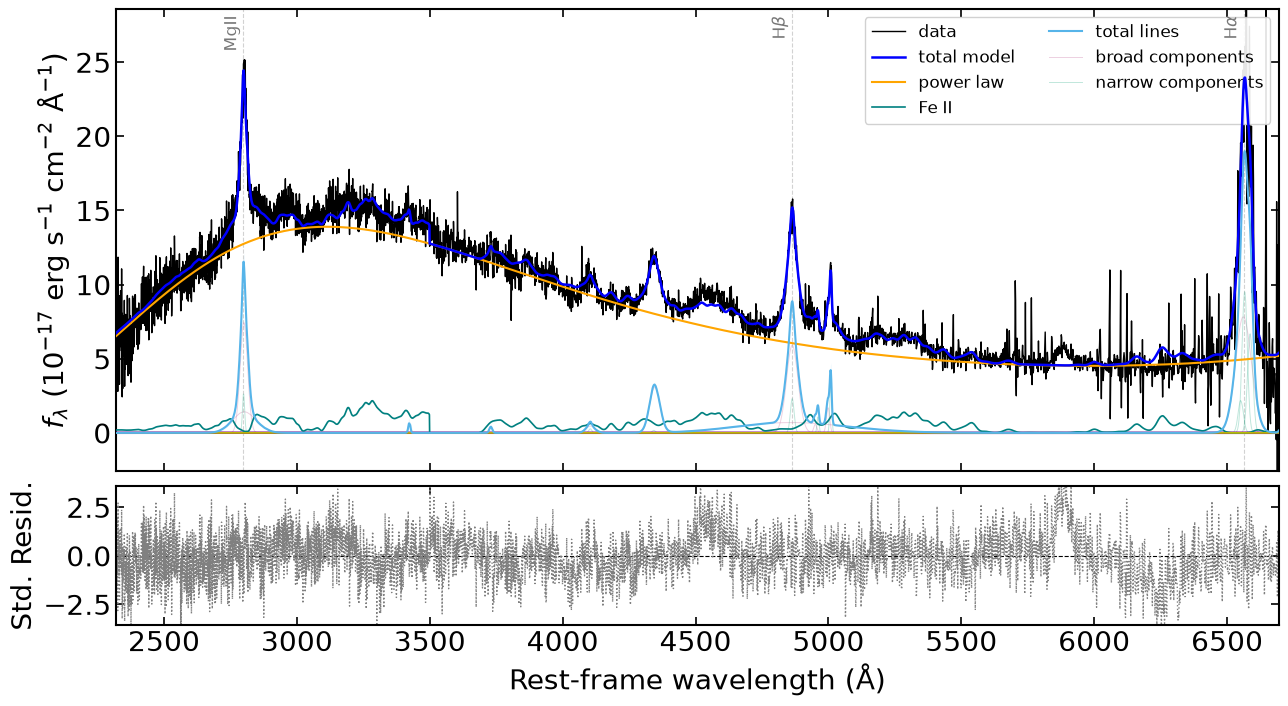

In [3]:
config = FitConfig(
    observation=Observation(object_id="J010514", redshift=z, ra=coord.ra.deg, dec=coord.dec.deg),
    spectroscopy=SpectroscopyData(wave_obs=wave, fluxes=flux, errors=err, resolving_power=resolving_power),
    continuum=ContinuumConfig(fit_feii=True, fit_balmer_continuum=False),
    host=HostConfig(enabled=True, dsps_ssp_fn="../tempdata.h5"),
    lines=LineConfig(enabled=True),
    inference=InferenceConfig(method="optax+nuts", map_steps=600, num_warmup=50, num_samples=50),
    output=OutputConfig(save_result=False, save_fig=False, show_plot=True),
)

fiber_fitter = JAXQSOFit(config)
fiber_result = fiber_fitter.fit(verbose=False)

## 3. Fit with the PSF photometry

The only change is `psf_photometry`. Bands that do not overlap the spectrum are dropped, because `jaxqsofit` cannot model flux outside the fitted spectral window; use `jaxsedfit` for photometry beyond the spectrum or for a full host + AGN SED. `plot_psf_space=True` adds the PSF-space model and the synthetic photometry to the figure.


                                           mean       std    median      5.0%     95.0%     n_eff     r_hat
                          Fe_FWHM_std     -1.03      0.08     -1.03     -1.16     -0.89     66.58      1.02
                         Fe_shift_std      1.51      0.21      1.51      1.19      1.84     72.30      1.01
                       Fe_uv_norm_std      5.13      0.07      5.13      5.00      5.22     32.05      0.98
             PL_apparent_log_norm_std      0.83      0.00      0.83      0.82      0.83     14.98      0.98
                PL_apparent_slope_std      0.13      0.02      0.13      0.10      0.17     26.39      0.98
                      delta_m_psf_raw     -0.05      0.06     -0.05     -0.14      0.03    188.38      0.98
                          eta_psf_raw      0.51      0.19      0.54      0.27      0.80     45.04      0.99
                      frac_jitter_std     -1.57      0.43     -1.55     -2.36     -1.02     54.74      1.04
                           

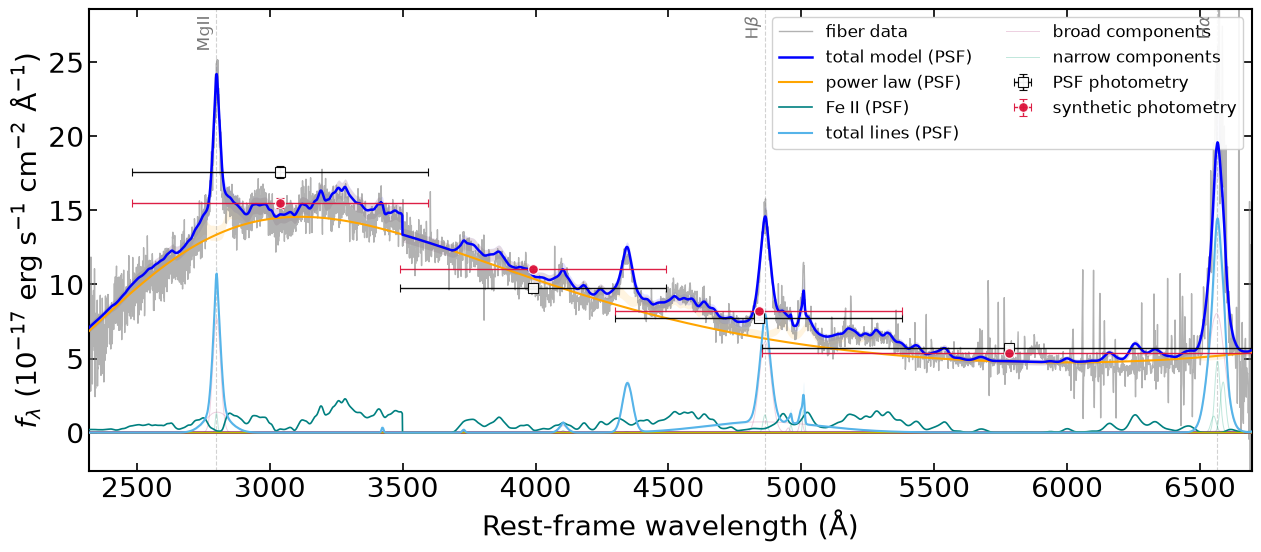

Bands used: ['g', 'r', 'i', 'z']


In [4]:
psf_config = replace(
    config,
    psf_photometry=PSFPhotometryData(magnitudes=psf_mags, magnitude_errors=psf_mag_errs, filter_names=bands),
)

psf_fitter = JAXQSOFit(psf_config)
psf_result = psf_fitter.fit(verbose=False, kwargs_plot={"plot_psf_space": True})
print("Bands used:", psf_fitter.psf_bands)

## 4. Compare the two fits

The PSF fit reports the gray offset `delta_m_psf` and the host suppression `eta_psf` between the fiber and PSF apertures.

In [5]:
for name, fitter in [("fiber only", fiber_fitter), ("fiber + PSF", psf_fitter)]:
    host, _ = fitter.component_fraction_at_wave("host", wave0=4200.0)
    print(f"{name:12s} host fraction at 4200 Å = {host:.2f}")
print(f"delta_m_psf = {psf_fitter.delta_m_psf:.3f} ± {psf_fitter.delta_m_psf_err:.3f} mag")
print(f"eta_psf     = {psf_fitter.eta_psf:.3f} ± {psf_fitter.eta_psf_err:.3f}")

fiber only   host fraction at 4200 Å = 0.00
fiber + PSF  host fraction at 4200 Å = 0.00
delta_m_psf = -0.050 ± 0.057 mag
eta_psf     = 0.540 ± 0.190


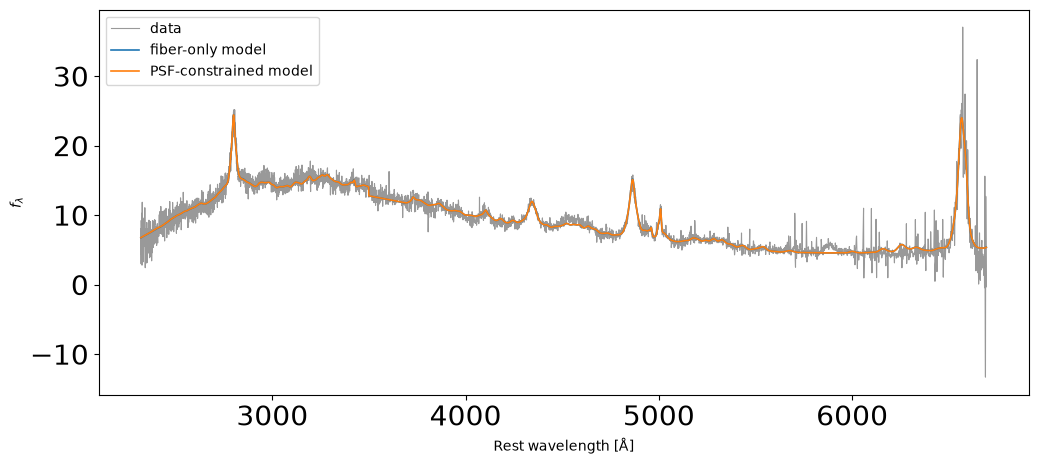

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(fiber_fitter.wave, fiber_fitter.flux, color="0.6", lw=0.8, label="data")
ax.plot(fiber_fitter.wave, fiber_fitter.model_total, lw=1.2, label="fiber-only model")
ax.plot(psf_fitter.wave, psf_fitter.model_total, lw=1.2, label="PSF-constrained model")
ax.set_xlabel("Rest wavelength [Å]")
ax.set_ylabel(r"$f_\lambda$")
ax.legend();